# Topological Accessibility of Shopping Malls in Medellín
## Persistent Homology via Cubical Complexes — Proof of Concept

**Research question:** Can persistent homology reveal the spatial structure of accessibility to shopping malls, detecting service voids and fragmented access patterns that standard coverage metrics miss?

**Workflow:**
1. Load the Medellín street network (GraphML)
2. Divide the city into 100 m × 100 m grid cells
3. Locate shopping malls from OpenStreetMap
4. Compute walking times from each cell centroid to the nearest mall (OSRM public API)
5. Build a sublevel-set cubical filtration: $f(\text{cell}) = $ walking time to nearest mall
6. Compute $H_0$ and $H_1$ persistent homology using GUDHI
7. Visualise persistence diagrams, barcodes, and the filtration's spatial evolution

## 0 · Dependencies

In [39]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec
import folium
from shapely.geometry import Point, Polygon
from shapely.ops import unary_union
import osmnx as ox
import networkx as nx
import requests
import json
import gudhi
from scipy.sparse.csgraph import dijkstra
from shapely.geometry import box, Point, Polygon

from scipy.spatial import cKDTree
import scipy.sparse as sp
from pathlib import Path
import time

# Paths
PROJECT_ROOT = Path('/Users/gregorioperez/Documents/Maestria/Investigacion/urban_form/15_min_city_ph')
DATA_DIR = PROJECT_ROOT / 'data'
FIGS_DIR = PROJECT_ROOT / 'figs'
RESULTS_DIR = PROJECT_ROOT / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
def find_repo_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "graph_kernels").exists() and (candidate / "levelset_urban_ph").exists():
            return candidate
    raise FileNotFoundError(f"Could not find urban_form repository from {start.resolve()}")

REPO_ROOT = find_repo_root()
CITY_PH_ROOT = REPO_ROOT / "15_min_city_ph"
FIGS_DIR = CITY_PH_ROOT / "figs"
FIGS_DIR.mkdir(parents=True, exist_ok=True)

# Constants
UTM_CRS = 'EPSG:32618'
WGS84 = 'EPSG:4326'
WALK_KMH = 4.7  # pedestrian speed in km/h (calibrated to match Valhalla)
WALK_M_PER_MIN = WALK_KMH * 1000.0 / 60.0
SENTINEL = 120.0  # unreachable cells
BBOX = (6.10, -75.70, 6.40, -75.44)  # Medellín


print(f'NumPy   {np.__version__}')
print(f'GeoPandas {gpd.__version__}')
print(f'OSMnx   {ox.__version__}')
print(f'GUDHI   {gudhi.__version__}')
print('All imports OK ✓')

NumPy   1.26.4
GeoPandas 1.1.2
OSMnx   2.0.7
GUDHI   3.11.0
All imports OK ✓


## 1 · Load the Medellín Street Network

In [27]:
GRAPHML_PATH = '/Users/gregorioperez/Documents/Maestria/Investigacion/urban_form/15_min_city_ph/medellin_drive_with_elevation.graphml'

print('Loading GraphML …')
G = ox.load_graphml(GRAPHML_PATH)
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G)

print(f'Nodes: {len(nodes_gdf):,}   Edges: {len(edges_gdf):,}')
print(f'CRS   : {nodes_gdf.crs}')
bounds = nodes_gdf.total_bounds  # coordinates are expressed in nodes_gdf.crs
print(f'Bounds ({nodes_gdf.crs}): x=[{bounds[0]:.4f}, {bounds[2]:.4f}]  y=[{bounds[1]:.4f}, {bounds[3]:.4f}]')

Loading GraphML …
Nodes: 15,207   Edges: 36,725
CRS   : epsg:4326
Bounds (epsg:4326): x=[-75.6445, -75.5270]  y=[6.1773, 6.3121]


## 2 · Divide Medellín into 100 m × 100 m Grid Cells

We reproject to a metric CRS (UTM zone 18N, EPSG:32618) to create the grid in metres, then project back to WGS-84 for downstream work.

In [52]:
CELL_SIZE_M = 100       # grid resolution in metres
ROAD_COVERAGE_M = 500   # include cells up to this distance from a road
UTM_CRS = 'EPSG:32618'  # UTM zone 18N covers Medellín
WGS84   = 'EPSG:4326'

# ── Normalize graph layers to both metric UTM and geographic WGS-84 ─────────
# The current GraphML is already EPSG:32618, while older versions were WGS-84.
# Deriving both views from the CRS metadata prevents double projection and
# ensures that layers plotted together always use the same coordinates.
if nodes_gdf.crs is None or edges_gdf.crs is None:
    raise ValueError('The GraphML has no CRS metadata; set its true CRS before continuing.')

nodes_utm = nodes_gdf.to_crs(UTM_CRS)
edges_utm = edges_gdf.to_crs(UTM_CRS)
nodes_wgs = nodes_gdf.to_crs(WGS84)
edges_wgs = edges_gdf.to_crs(WGS84)

# ── Generate a regular 100 m grid over the road-network extent ───────────────
minx, miny, maxx, maxy = edges_utm.total_bounds
xs = np.arange(minx, maxx, CELL_SIZE_M)
ys = np.arange(miny, maxy, CELL_SIZE_M)

grid_cells_utm = []
for x in xs:
    for y in ys:
        cell = box(x, y, x + CELL_SIZE_M, y + CELL_SIZE_M)
        grid_cells_utm.append(cell)

grid_candidates = gpd.GeoDataFrame({'geometry': grid_cells_utm}, crs=UTM_CRS)

# ── Road-neighborhood mask ──────────────────────────────────────────────────
# A convex hull fills every gap between distant road branches, whereas strict
# road intersection leaves parcels enclosed by roads blank. Keep cells that
# intersect a road OR lie within ROAD_COVERAGE_M of one. For a 100 m grid, a
# 100 m neighborhood usually fills local blocks without bridging remote roads.
# The unique index removes duplicates when several road segments hit one cell.
road_hits = gpd.sjoin(
    grid_candidates,
    edges_utm[['geometry']],
    how='inner',
    predicate='dwithin',
    distance=ROAD_COVERAGE_M,
)
road_cell_idx = road_hits.index.unique()
grid_gdf = grid_candidates.loc[road_cell_idx].copy().reset_index(drop=True)

# ── Add centroid coords in WGS-84 for routing ────────────────────────────────
grid_gdf['centroid_utm'] = grid_gdf.geometry.centroid
centroids_wgs = (
    gpd.GeoDataFrame(geometry=grid_gdf['centroid_utm'], crs=UTM_CRS)
    .to_crs(WGS84)
    .geometry
)
grid_gdf['centroid_lon'] = centroids_wgs.x
grid_gdf['centroid_lat'] = centroids_wgs.y
perim = grid_gdf.geometry.union_all()
# ── Grid index bookkeeping (row/col for cubical complex) ────────────────────
n_cols = len(xs)
n_rows = len(ys)

print(f'Grid cells (full network extent): {len(xs) * len(ys):,}')
print(f'Grid cells within {ROAD_COVERAGE_M:.0f} m of roads: {len(grid_gdf):,}')
print(f'Grid dimensions: {n_rows} rows × {n_cols} cols')

Grid cells (full network extent): 19,500
Grid cells within 500 m of roads: 13,298
Grid dimensions: 150 rows × 130 cols


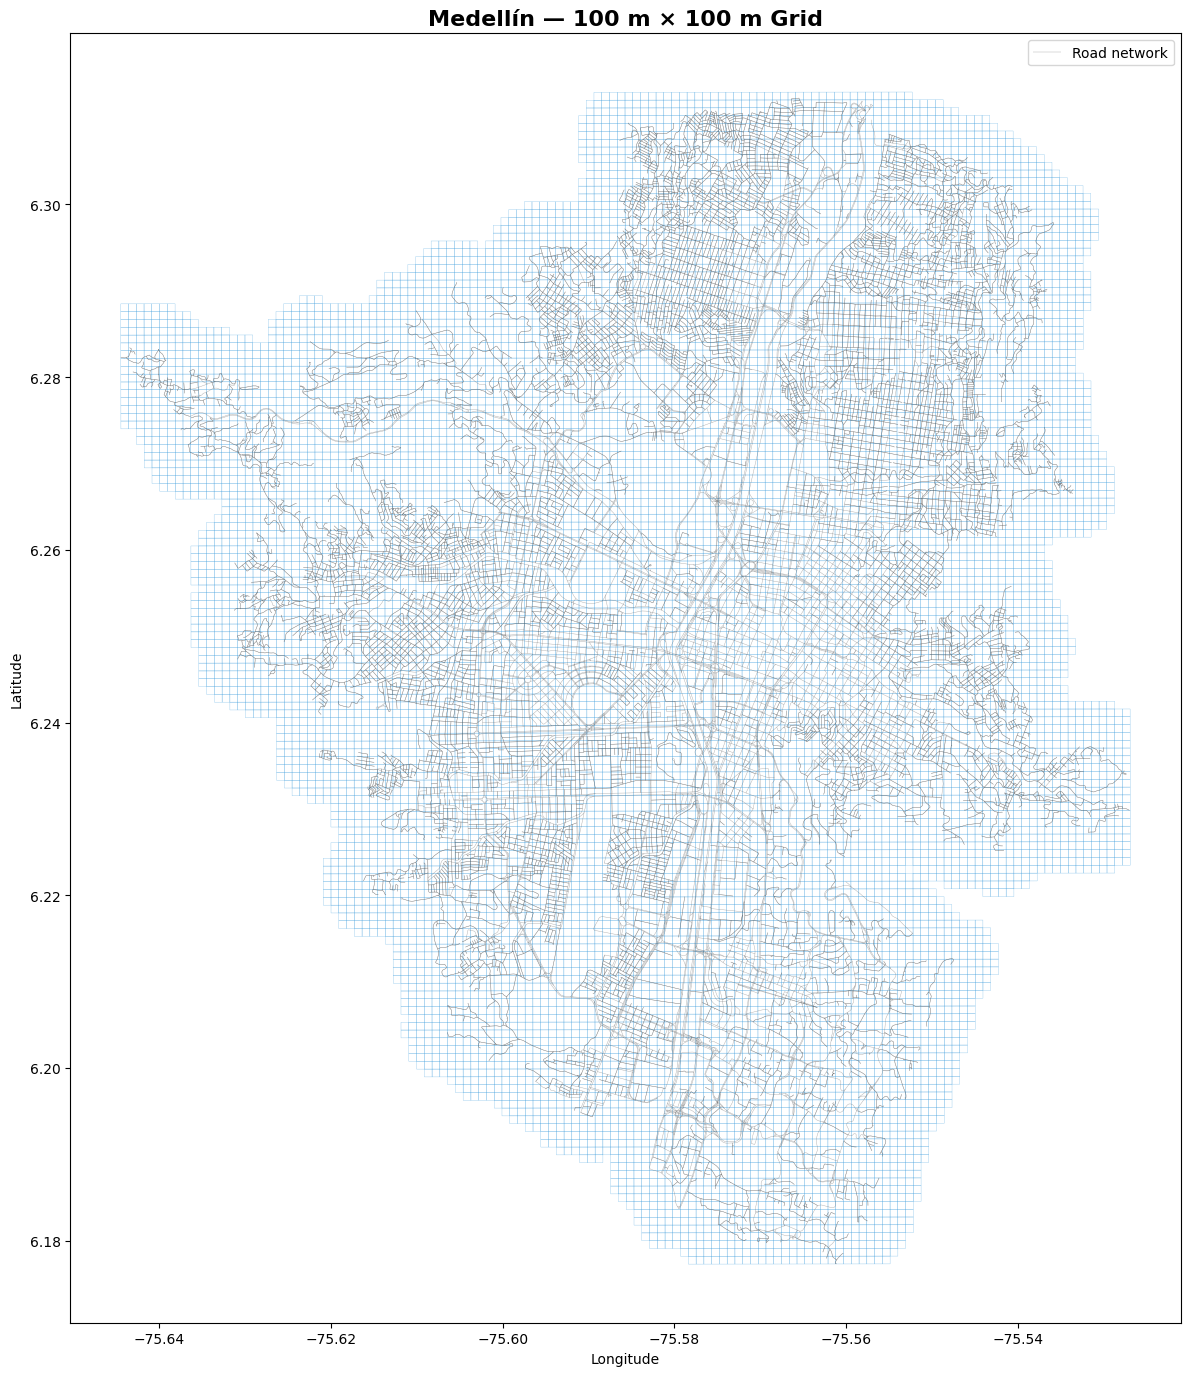

Saved fig01_grid.png


In [53]:
# ── Plot: 100 m grid over the Medellín road network ─────────────────────────
fig, ax = plt.subplots(figsize=(12, 14))

# Road network edges (WGS-84)
edges_wgs.plot(ax=ax, linewidth=0.3, color='#555555', alpha=0.5, label='Road network')

# Grid cells (reproject back to WGS-84 for consistent axes)
grid_wgs = grid_gdf.to_crs(WGS84)

grid_wgs.plot(ax=ax, facecolor='none', edgecolor='#3498db', linewidth=0.25, alpha=0.6, label='100 m cells')

ax.set_title('Medellín — 100 m × 100 m Grid', fontsize=16, fontweight='bold')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig01_grid.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved fig01_grid.png')

## 3 · Shopping Mall Locations

We fetch mall locations directly from OpenStreetMap via the Overpass API, replicating the query from `centros_comerciales.ipynb`.

In [54]:
BBOX = (6.10, -75.70, 6.40, -75.44)  # Medellín

def fetch_malls_osm(
    bbox=BBOX,
    tags=None,
    retries=3,
    delay=10
):
    """Query Overpass API for hospitals and clinics."""

    if tags is None:
        tags = [
            "shop=mall",
            "building=retail",
        ]

    south, west, north, east = bbox

    query = "[out:json][timeout:180];("
    for tag in tags:
        key, value = tag.split("=", maxsplit=1)
        query += (
            f'nwr["{key}"="{value}"]'
            f"({south},{west},{north},{east});"
        )
    query += ");out center tags;"

    url = "https://overpass-api.de/api/interpreter"

    headers = {
        # Replace the email with your real contact information
        "User-Agent": "UrbanHospitalResearch/1.0 (contact: greg2222@gmail.com)",
        "Accept": "application/json",
    }

    for attempt in range(retries):
        try:
            print(f"[{attempt + 1}/{retries}] Querying Overpass API...")

            response = requests.post(
                url,
                data={"data": query},
                headers=headers,
                timeout=300,
            )

            # Print Overpass's explanation before raising the exception
            if not response.ok:
                print(f"HTTP {response.status_code}")
                print(response.text[:1000])

            response.raise_for_status()

            result = response.json()
            return result.get("elements", [])

        except requests.exceptions.RequestException as error:
            if attempt < retries - 1:
                print(f"Attempt {attempt + 1} failed: {error}")
                time.sleep(delay)
            else:
                raise



elements = fetch_malls_osm()

print(f'Raw Overpass elements: {len(elements)}')

[1/3] Querying Overpass API...
Raw Overpass elements: 249


In [55]:
recs = []
for e in elements:
    lon = e.get('lon', (e.get('center') or {}).get('lon'))
    lat = e.get('lat', (e.get('center') or {}).get('lat'))
    if lon is None or lat is None:
        continue
    tags = e.get('tags') or {}
    recs.append({
        'osm_id': f"{e['type']}/{e['id']}",
        'name': tags.get('name'),
        'amenity': tags.get('amenity'),
        'lon': lon,
        'lat': lat
    })

df = pd.DataFrame(recs).drop_duplicates('osm_id')
malls_gdf = gpd.GeoDataFrame(
    df,
    geometry=[Point(a, b) for a, b in zip(df.lon, df.lat)],
    crs=WGS84
).to_crs(UTM_CRS)

print(f'Before dedup: {len(malls_gdf)}')

# Collapse co-located same-name duplicates
named = malls_gdf[malls_gdf.name.notna() & (malls_gdf.name.str.strip() != '')].copy()
unnamed = malls_gdf[~malls_gdf.index.isin(named.index)]


named['_k'] = (
    named.name.str.strip().str.lower() + '|' +
    (named.geometry.x // 60).astype(int).astype(str) + '|' +
    (named.geometry.y // 60).astype(int).astype(str)
)
named = named.drop_duplicates('_k').drop(columns='_k')
unnamed = pd.concat([named, unnamed], ignore_index=True)

# Clip to perimeter
malls_gdf = malls_gdf[malls_gdf.within(perim)].reset_index(drop=True)

print(f'After dedup & clipping: {len(malls_gdf)} facilities')
print(f'\nFacility types:\n{malls_gdf["amenity"].value_counts()}')

Before dedup: 249
After dedup & clipping: 201 facilities

Facility types:
amenity
fast_food    1
Name: count, dtype: int64


## 4 · Compute Walking Times to Nearest Mall

We use the **OSRM public API** (Project-OSRM) table endpoint with the `foot` profile.  
The API accepts a list of coordinates; we supply grid-cell centroids as *sources* and mall locations as *destinations*, and it returns a duration matrix (seconds).  

To stay within the public API's rate limits we send batches of ≤ 150 source cells at a time.

Loading cached walk network
Walk network: 50,441 nodes, 144,356 edges


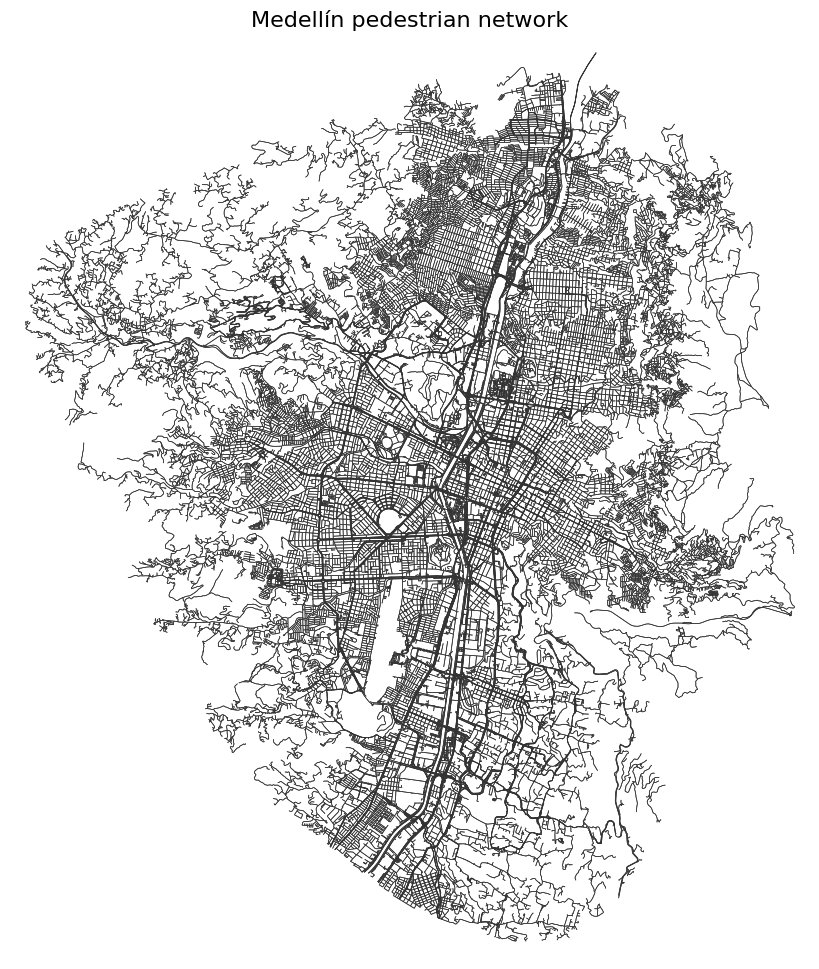

In [56]:
walk_graph_cache = DATA_DIR / 'medellin_walk.graphml'

if walk_graph_cache.exists():
    print(f'Loading cached walk network')
    Gu = ox.load_graphml(walk_graph_cache)
else:
    print('Building pedestrian network from OSM...')
    perim_wgs = gpd.GeoSeries([perim], crs=UTM_CRS).to_crs(WGS84).iloc[0]
    perim_buffered = perim_wgs.buffer(0.02)
    G = ox.graph_from_polygon(perim_buffered, network_type='walk', simplify=True)
    Gu = ox.convert.to_undirected(G)
    Gu = Gu.subgraph(max(nx.connected_components(Gu), key=len)).copy()
    ox.save_graphml(Gu, walk_graph_cache)

print(f'Walk network: {Gu.number_of_nodes():,} nodes, {Gu.number_of_edges():,} edges')


fig, ax = ox.plot_graph(
    Gu,
    figsize=(12, 12),
    bgcolor="white",
    node_size=0,
    edge_color="#333333",
    edge_linewidth=0.5,
    show=False,
    close=False,
)

ax.set_title("Medellín pedestrian network", fontsize=16)
plt.show()

In [57]:
# %%
print('Building sparse adjacency matrix...')
nodes = list(Gu.nodes())
node_idx = {n: i for i, n in enumerate(nodes)}

node_xy = np.array([[Gu.nodes[n]['x'], Gu.nodes[n]['y']] for n in nodes])
node_utm = gpd.GeoSeries([Point(x, y) for x, y in node_xy], crs=WGS84).to_crs(UTM_CRS)
node_coords_utm = np.c_[node_utm.x, node_utm.y]
tree = cKDTree(node_coords_utm)

# Build CSR matrix (collapse parallel edges)
best_edges = {}
for u, v, d in Gu.edges(data=True):
    i, j = node_idx[u], node_idx[v]
    key = (i, j) if i < j else (j, i)
    length_m = float(d.get('length', 0.0))
    time_min = length_m / WALK_M_PER_MIN
    if key not in best_edges or time_min < best_edges[key]:
        best_edges[key] = time_min

rows, cols, weights = [], [], []
for (i, j), t in best_edges.items():
    rows += [i, j]
    cols += [j, i]
    weights += [t, t]

A = sp.csr_matrix((weights, (rows, cols)), shape=(len(nodes), len(nodes)))
print(f'Adjacency matrix: {A.nnz} edges')

Building sparse adjacency matrix...
Adjacency matrix: 143383 edges


In [58]:
print('Snapping grid centroids...')
grid_coords_utm = np.c_[grid_gdf.centroid_utm.x, grid_gdf.centroid_utm.y]
_, grid_nodes = tree.query(grid_coords_utm)

print(f'Snapping {len(malls_gdf)} malls...')
malls_coords_utm = np.c_[malls_gdf.geometry.x, malls_gdf.geometry.y]
_, malls_nodes = tree.query(malls_coords_utm)

# Multi-source Dijkstra
print('Running Dijkstra...')
unique_malls_nodes = np.unique(malls_nodes)
dist = dijkstra(A, directed=False, indices=unique_malls_nodes, min_only=True)

walking_times = dist[grid_nodes]
walking_times = np.where(np.isfinite(walking_times), walking_times, SENTINEL)
grid_gdf['t_malls'] = walking_times

cov_15 = (walking_times <= 15.0).sum()
cov_30 = (walking_times <= 30.0).sum()
print(f'\nWalking times computed:')
print(f'  Min: {np.nanmin(walking_times):.1f} min')
print(f'  Mean: {np.nanmean(walking_times):.1f} min')
print(f'  Median: {np.nanmedian(walking_times):.1f} min')
print(f'  Max: {np.nanmax(walking_times):.1f} min')
print(f'\nCoverage:')
print(f'  15 min: {cov_15:,} cells ({100*cov_15/len(grid_gdf):.1f}%)')
print(f'  30 min: {cov_30:,} cells ({100*cov_30/len(grid_gdf):.1f}%)')

Snapping grid centroids...
Snapping 201 malls...
Running Dijkstra...

Walking times computed:
  Min: 0.0 min
  Mean: 15.9 min
  Median: 13.1 min
  Max: 117.4 min

Coverage:
  15 min: 7,540 cells (56.7%)
  30 min: 11,953 cells (89.9%)


## 5 · Build the Cubical Complex Filtration

### Conceptual setup

We construct a **sublevel-set filtration** on a regular 2-D grid:

$$f(\text{cell}) = \text{walking time to nearest mall (minutes)}$$

At threshold $t$, we include all cells with $f(\text{cell}) \le t$:

$$A_t = \{\text{cell} : f(\text{cell}) \le t\}$$

GUDHI's `CubicalComplex` takes the grid as a 2-D array where each entry is the *filtration value* of the corresponding top-dimensional cell (a 2-D square). It automatically derives the filtration values of the lower-dimensional faces (edges, vertices) via the lower-star rule.

The **key topological features** we interpret:
- **$H_0$** (connected components): accessibility *islands* — disconnected pockets of access
- **$H_1$** (loops / holes): service *voids* — regions of poor access surrounded by accessible areas

In [66]:
# ── Build a 2-D grid array aligned with the (row, col) UTM grid ──────────────
# We need to assign each grid cell its (row, col) index so we can fill
# a 2-D matrix for the cubical complex.

xs_arr = np.arange(minx, maxx, CELL_SIZE_M)
ys_arr = np.arange(miny, maxy, CELL_SIZE_M)

# Recompute cell indices in the full (n_rows × n_cols) grid
# centroids in UTM
cx_utm = grid_gdf['centroid_utm'].apply(lambda g: g.x).values
cy_utm = grid_gdf['centroid_utm'].apply(lambda g: g.y).values

col_idx = ((cx_utm - minx) / CELL_SIZE_M).astype(int)
row_idx = ((cy_utm - miny) / CELL_SIZE_M).astype(int)

col_idx = np.clip(col_idx, 0, len(xs_arr) - 1)
row_idx = np.clip(row_idx, 0, len(ys_arr) - 1)

grid_gdf['col_idx'] = col_idx
grid_gdf['row_idx'] = row_idx

# ── Fill the 2-D filtration matrix ───────────────────────────────────────────
# Cells outside the road-neighborhood analysis domain are set to SENTINEL.
filtration_matrix = np.full((len(ys_arr), len(xs_arr)), SENTINEL)

for idx, row in grid_gdf.iterrows():
    r = int(row['row_idx'])
    c = int(row['col_idx'])
    filtration_matrix[r, c] = row['t_malls']

print(f'Filtration matrix shape: {filtration_matrix.shape}  ({filtration_matrix.shape[0] * filtration_matrix.shape[1]:,} cells)')
print(f'Values in [0, {filtration_matrix.max():.1f}] min')
print(f'Cells ≤ 15 min: {(filtration_matrix <= 15).sum():,}')
print(f'Cells ≤ 30 min: {(filtration_matrix <= 30).sum():,}')

Filtration matrix shape: (150, 130)  (19,500 cells)
Values in [0, 120.0] min
Cells ≤ 15 min: 7,540
Cells ≤ 30 min: 11,953


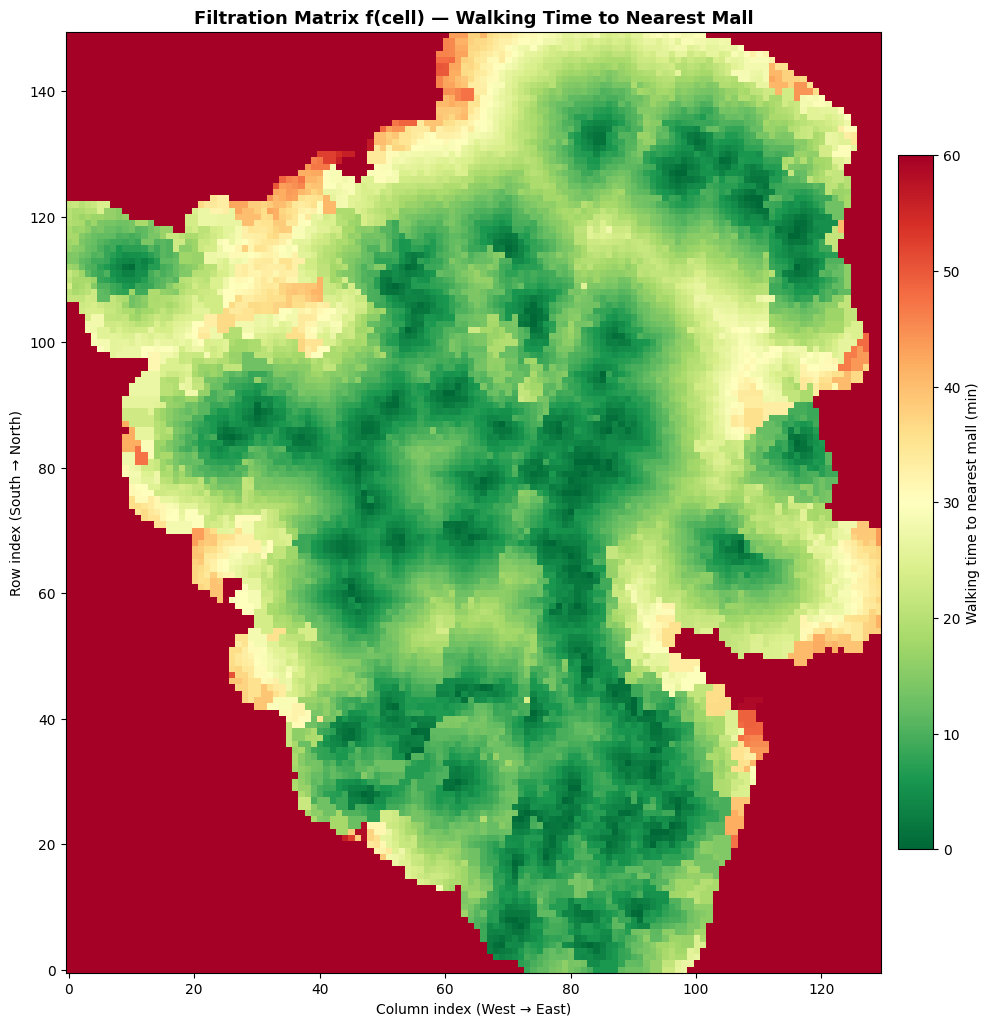

Saved fig04_filtration_matrix.png


In [67]:
# ── Plot: Filtration matrix as a heatmap ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 12))

im = ax.imshow(
    filtration_matrix,
    origin='lower',
    cmap='RdYlGn_r',
    vmin=0, vmax=60,
    interpolation='nearest'
)
cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label('Walking time to nearest mall (min)', fontsize=10)

ax.set_title('Filtration Matrix f(cell) — Walking Time to Nearest Mall', fontsize=13, fontweight='bold')
ax.set_xlabel('Column index (West → East)')
ax.set_ylabel('Row index (South → North)')
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig04_filtration_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig04_filtration_matrix.png')

### 5.1 · Filtration snapshots — how $A_t$ evolves

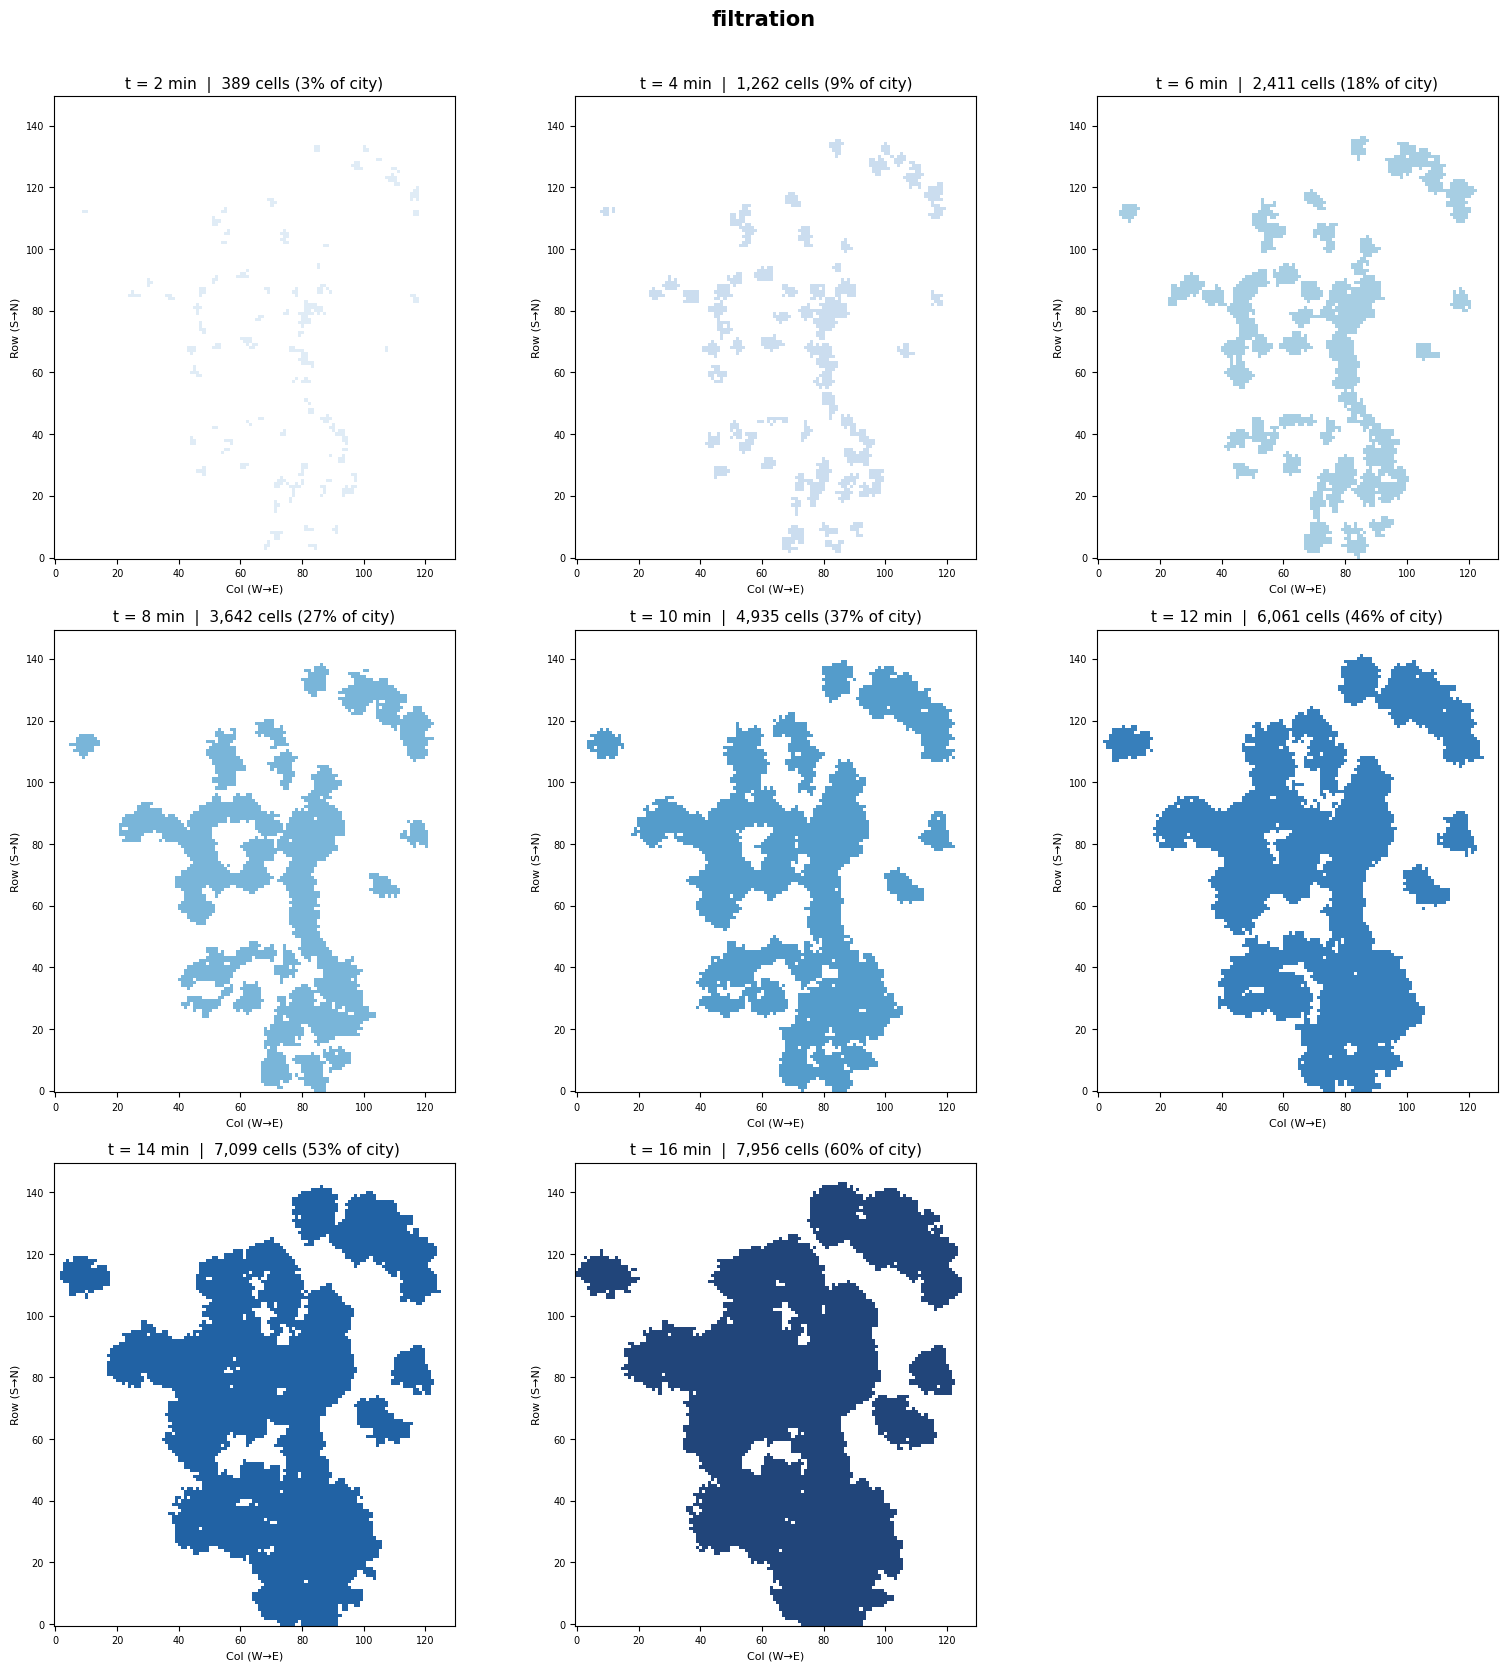

Saved fig05_filtration_snapshots.png


In [70]:
# ── Spatial maps of the sublevel sets at increasing thresholds ────────────────
THRESHOLDS = [2,4,6,8,10,12,14,16]
NCOLS = 3
NROWS = int(np.ceil(len(THRESHOLDS) / NCOLS))

fig, axes = plt.subplots(NROWS, NCOLS, figsize=(16, NROWS * 5.5))
axes = axes.flatten()

for i, t in enumerate(THRESHOLDS):
    ax = axes[i]

    # Binary mask: included at threshold t?
    included = filtration_matrix <= t
    disp = np.where(included, t, np.nan)

    ax.imshow(
        disp,
        origin='lower',
        cmap='Blues',
        vmin=0, vmax=max(THRESHOLDS),
        interpolation='nearest',
        alpha=0.9
    )

    pct = 100 * included.sum() / (filtration_matrix < SENTINEL).sum()
    ax.set_title(f't = {t} min  |  {included.sum():,} cells ({pct:.0f}% of city)', fontsize=11)
    ax.set_xlabel('Col (W→E)', fontsize=8)
    ax.set_ylabel('Row (S→N)', fontsize=8)
    ax.tick_params(labelsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    'filtration',
    fontsize=15, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig05_filtration_snapshots.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig05_filtration_snapshots.png')

## 6 · Persistent Homology with GUDHI CubicalComplex

In [71]:
# ── Build the cubical complex ─────────────────────────────────────────────────
# GUDHI's CubicalComplex needs:
#   dimensions = [n_rows, n_cols]  (row-major)
#   top_dimensional_cells = flat list of cell filtration values

print('Building CubicalComplex …')
cc = gudhi.CubicalComplex(
    dimensions=list(filtration_matrix.shape),
    top_dimensional_cells=filtration_matrix.flatten().tolist()
)

print('Computing persistence …')
cc.compute_persistence()

persistence = cc.persistence()  # list of (dim, (birth, death))

# Separate by dimension
h0 = [(b, d) for dim, (b, d) in persistence if dim == 0]
h1 = [(b, d) for dim, (b, d) in persistence if dim == 1]

print(f'\n$H_0$ pairs: {len(h0)}  (connected components)')
print(f'$H_1$ pairs: {len(h1)}  (loops / holes)')

# Filter out the point at infinity for statistics
h0_finite = [(b, d) for b, d in h0 if d < SENTINEL]
h1_finite = [(b, d) for b, d in h1 if d < SENTINEL]
print(f'\nFinite $H_0$: {len(h0_finite)}')
print(f'Finite $H_1$: {len(h1_finite)}')

if h0_finite:
    persis0 = [d-b for b,d in h0_finite]
    print(f'$H_0$ persistence  mean={np.mean(persis0):.2f}  max={np.max(persis0):.2f} min')
if h1_finite:
    persis1 = [d-b for b,d in h1_finite]
    print(f'$H_1$ persistence  mean={np.mean(persis1):.2f}  max={np.max(persis1):.2f} min')

Building CubicalComplex …
Computing persistence …

$H_0$ pairs: 870  (connected components)
$H_1$ pairs: 454  (loops / holes)

Finite $H_0$: 858
Finite $H_1$: 401
$H_0$ persistence  mean=3.47  max=44.76 min
$H_1$ persistence  mean=3.57  max=84.24 min


In [72]:
# ── Most persistent H1 features (service voids) ──────────────────────────────
h1_sorted = sorted(h1_finite, key=lambda x: x[1]-x[0], reverse=True)
print('Top 15 most persistent H₁ features (service voids):')
print(f'{"Birth":>10}  {"Death":>10}  {"Persistence":>13}  Interpretation')
print('-' * 65)
for b, d in h1_sorted[:15]:
    pers = d - b
    born_at  = f'{b:.1f} min'
    dead_at  = f'{d:.1f} min'
    pers_str = f'{pers:.1f} min'
    # Interpret relative to the 15-min threshold
    if b > 15:
        note = 'void persists well beyond 15-min'
    elif d > 15:
        note = 'void crosses 15-min boundary'
    else:
        note = 'void resolved within 15 min'
    print(f'{born_at:>10}  {dead_at:>10}  {pers_str:>13}  {note}')

Top 15 most persistent H₁ features (service voids):
     Birth       Death    Persistence  Interpretation
-----------------------------------------------------------------
  32.4 min   116.7 min       84.2 min  void persists well beyond 15-min
  38.4 min   117.4 min       79.0 min  void persists well beyond 15-min
  41.5 min   117.4 min       75.9 min  void persists well beyond 15-min
  42.1 min   117.4 min       75.3 min  void persists well beyond 15-min
  31.7 min    86.9 min       55.2 min  void persists well beyond 15-min
  21.4 min    41.1 min       19.6 min  void persists well beyond 15-min
  27.9 min    47.5 min       19.6 min  void persists well beyond 15-min
  22.4 min    41.1 min       18.7 min  void persists well beyond 15-min
  19.0 min    35.3 min       16.2 min  void persists well beyond 15-min
  24.9 min    41.1 min       16.2 min  void persists well beyond 15-min
  22.3 min    37.9 min       15.7 min  void persists well beyond 15-min
  22.8 min    38.2 min       15.4 mi

In [73]:
# ── H0 analysis ──────────────────────────────────────────────────────────────
h0_sorted = sorted(h0_finite, key=lambda x: x[1]-x[0], reverse=True)
print(f'H₀ pairs (accessibility islands that eventually merge):')
print(f'  Born before 15 min and dying after 15 min: '
      f'{sum(1 for b,d in h0_finite if b <= 15 < d)}')
print(f'  Persistent beyond 30 min: '
      f'{sum(1 for b,d in h0_finite if d > 30)}')

H₀ pairs (accessibility islands that eventually merge):
  Born before 15 min and dying after 15 min: 55
  Persistent beyond 30 min: 8


## 7 · Visualise: Persistence Diagrams and Barcodes

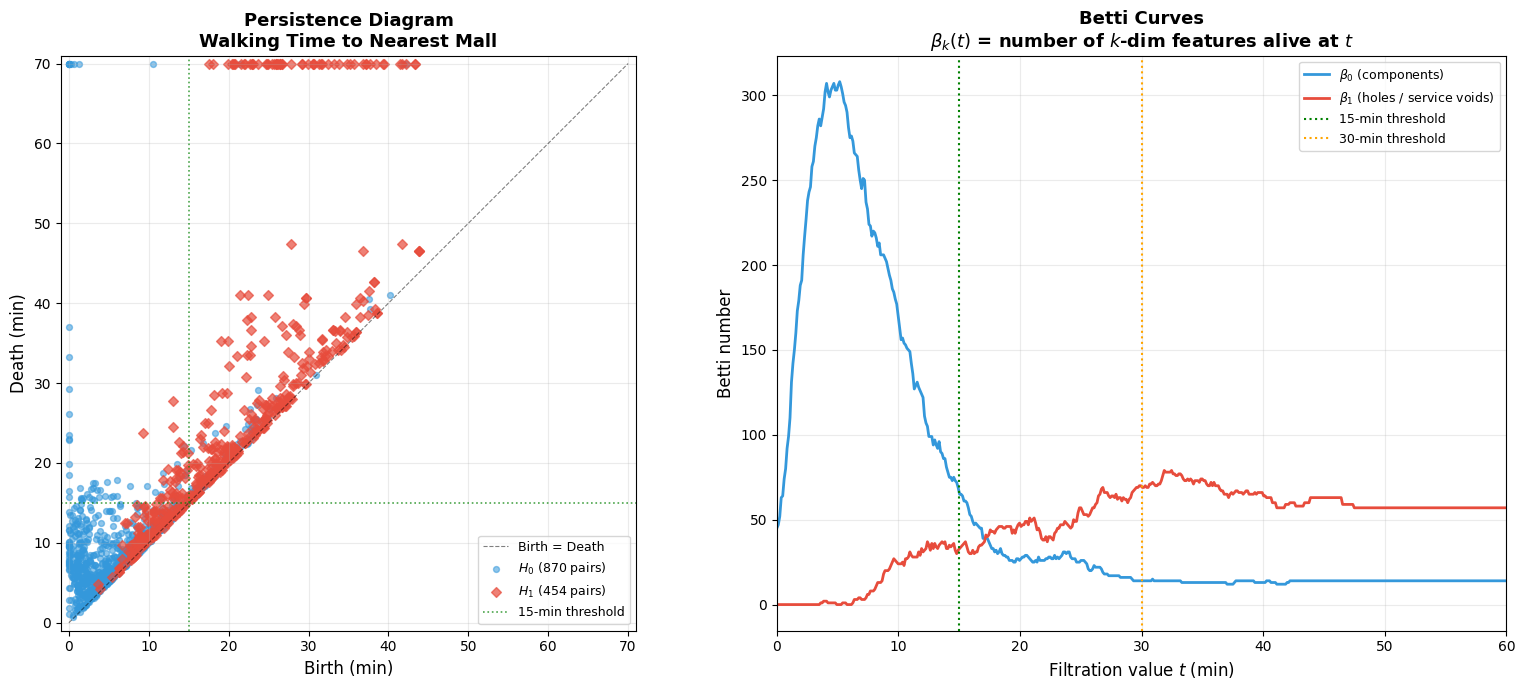

Saved fig06_persistence_diagram_betti.png


In [74]:
# ── Persistence diagram ───────────────────────────────────────────────────────
# Replace sentinel deaths with a finite display cap for plotting
PLOT_CAP = 70.0

def cap_persistence(pairs, cap=PLOT_CAP):
    return [(b, min(d, cap)) for b, d in pairs]

h0_plot = cap_persistence(h0)
h1_plot = cap_persistence(h1)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Persistence diagram (manual, so we can style both dims together)
ax = axes[0]
lim = PLOT_CAP

# Diagonal
ax.plot([0, lim], [0, lim], 'k--', lw=0.8, alpha=0.5, label='Birth = Death')

# H0
births0, deaths0 = zip(*h0_plot) if h0_plot else ([], [])
ax.scatter(births0, deaths0, c='#3498db', s=18, alpha=0.55, label=f'$H_0$ ({len(h0)} pairs)')

# H1
if h1_plot:
    births1, deaths1 = zip(*h1_plot)
    ax.scatter(births1, deaths1, c='#e74c3c', s=25, alpha=0.7, marker='D',
               label=f'$H_1$ ({len(h1)} pairs)')

# 15-min reference lines
ax.axvline(15, color='green', ls=':', lw=1.2, alpha=0.7, label='15-min threshold')
ax.axhline(15, color='green', ls=':', lw=1.2, alpha=0.7)

ax.set_xlim(-1, lim + 1)
ax.set_ylim(-1, lim + 1)
ax.set_xlabel('Birth (min)', fontsize=12)
ax.set_ylabel('Death (min)', fontsize=12)
ax.set_title('Persistence Diagram\nWalking Time to Nearest Mall', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
ax.set_aspect('equal')
ax.grid(True, alpha=0.25)

# ── Betti number curves ───────────────────────────────────────────────────────
ax2 = axes[1]
t_range = np.linspace(0, 60, 500)

def betti_curve(pairs, t_vals):
    """Count how many pairs have birth <= t < death."""
    counts = []
    for t in t_vals:
        c = sum(1 for b, d in pairs if b <= t < d)
        counts.append(c)
    return np.array(counts)

b0 = betti_curve(h0, t_range)
b1 = betti_curve(h1, t_range)

ax2.plot(t_range, b0, color='#3498db', lw=2.0, label='$\\beta_0$ (components)')
ax2.plot(t_range, b1, color='#e74c3c', lw=2.0, label='$\\beta_1$ (holes / service voids)')
ax2.axvline(15, color='green', ls=':', lw=1.5, label='15-min threshold')
ax2.axvline(30, color='orange', ls=':', lw=1.5, label='30-min threshold')

ax2.set_xlabel('Filtration value $t$ (min)', fontsize=12)
ax2.set_ylabel('Betti number', fontsize=12)
ax2.set_title('Betti Curves\n$\\beta_k(t)$ = number of $k$-dim features alive at $t$', fontsize=13, fontweight='bold')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.25)
ax2.set_xlim(0, 60)

plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig06_persistence_diagram_betti.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig06_persistence_diagram_betti.png')

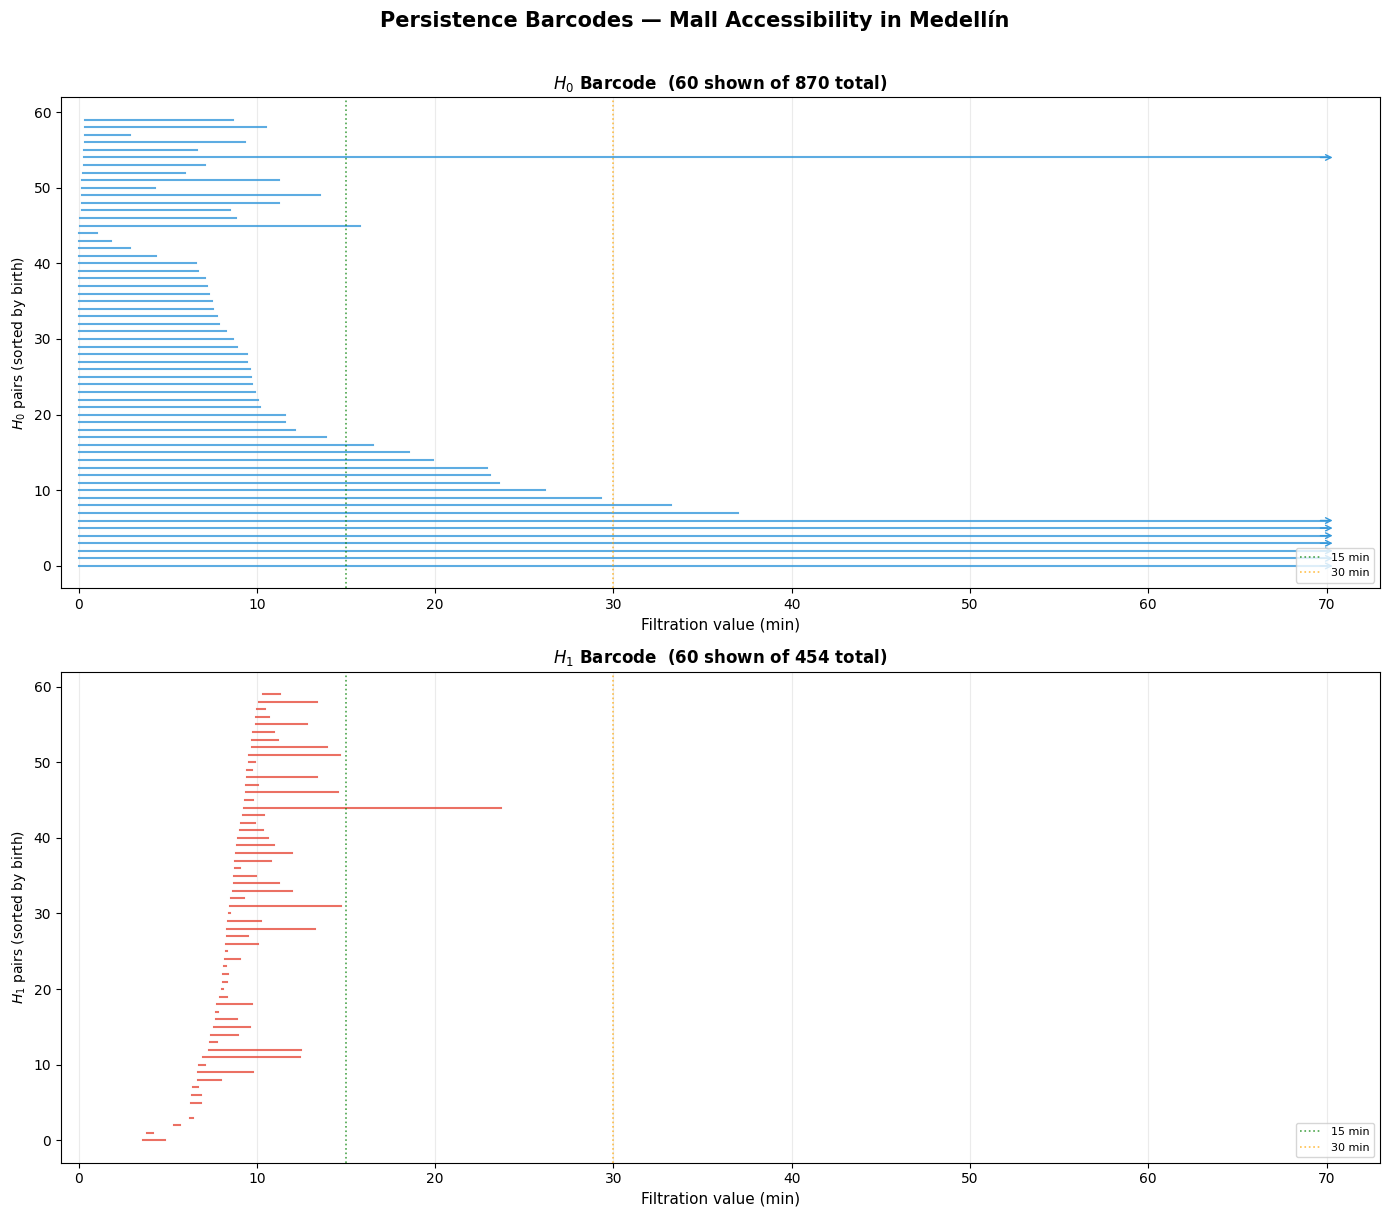

Saved fig07_barcodes.png


In [75]:
# ── Persistence Barcodes ──────────────────────────────────────────────────────
def plot_barcode(pairs, dim_label, color, ax, cap=PLOT_CAP, max_bars=80):
    """Draw a barcode for a list of (birth, death) pairs."""
    # Sort by birth, then persistence descending
    pairs_sorted = sorted(pairs, key=lambda x: (x[0], -(x[1]-x[0])))
    pairs_sorted = pairs_sorted[:max_bars]  # clip for readability

    for i, (b, d) in enumerate(pairs_sorted):
        d_plot = min(d, cap)
        ax.plot([b, d_plot], [i, i], color=color, lw=1.5, alpha=0.8)
        if d >= cap:
            ax.annotate('', xy=(cap + 0.5, i), xytext=(cap - 0.5, i),
                        arrowprops=dict(arrowstyle='->', color=color, lw=1.0))

    ax.axvline(15, color='green', ls=':', lw=1.2, alpha=0.7, label='15 min')
    ax.axvline(30, color='orange', ls=':', lw=1.2, alpha=0.7, label='30 min')
    ax.set_xlim(-1, cap + 3)
    ax.set_xlabel('Filtration value (min)', fontsize=11)
    ax.set_ylabel(f'{dim_label} pairs (sorted by birth)', fontsize=10)
    ax.set_title(f'{dim_label} Barcode  ({len(pairs_sorted)} shown of {len(pairs)} total)', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(axis='x', alpha=0.25)


fig, axes = plt.subplots(2, 1, figsize=(14, 12))
plot_barcode(h0, '$H_0$', '#3498db', axes[0], max_bars=60)
plot_barcode(h1, '$H_1$', '#e74c3c', axes[1], max_bars=60)

fig.suptitle('Persistence Barcodes — Mall Accessibility in Medellín', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig07_barcodes.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig07_barcodes.png')

## 8 · Topological Accessibility Indicators

We define three summary statistics inspired by the *Topological 15-Minute Score* proposed in the research framework.

In [76]:
THRESHOLD = 15.0  # the 15-minute city benchmark

# ── H0 Fragmentation Index ────────────────────────────────────────────────────
# Number of H0 features that are still alive (not yet merged) at t=15 min
h0_alive_15 = [(b, d) for b, d in h0 if b <= THRESHOLD < d]
fragmentation_index = len(h0_alive_15)

# ── H1 Service-Void Index ─────────────────────────────────────────────────────
# Total persistence of H1 features that survive beyond the 15-min threshold
h1_beyond_15 = [(b, d) for b, d in h1 if d > THRESHOLD and d < SENTINEL]
service_void_index = sum(d - b for b, d in h1_beyond_15)

# ── Coverage at 15 min ────────────────────────────────────────────────────────
city_cells = (filtration_matrix < SENTINEL).sum()
covered_15 = (filtration_matrix <= THRESHOLD).sum()
coverage_pct = 100 * covered_15 / city_cells

print('=' * 55)
print('  TOPOLOGICAL ACCESSIBILITY INDICATORS (15-min city)')
print('=' * 55)
print(f'  Standard coverage (cells ≤ 15 min)     : {coverage_pct:.1f}%')
print(f'  H₀ Fragmentation Index (β₀ at t=15)    : {fragmentation_index}')
print(f'  H₁ Service-Void Index (Σ pers, t>15)   : {service_void_index:.1f} min')
print(f'  H₁ voids that cross 15-min boundary    : {len(h1_beyond_15)}')
print(f'  H₁ voids born after 15 min             : {sum(1 for b,d in h1 if b > 15 and d < SENTINEL)}')
print('=' * 55)

print(f'''
Interpretation
──────────────
• {coverage_pct:.0f}% of city grid cells are within 15 min of a mall.
• At t=15 min, β₀={fragmentation_index}: the 15-min accessible region consists of
  {fragmentation_index} disconnected islands. A truly integrated city would show β₀→1.
• {len(h1_beyond_15)} H₁ holes (service voids) persist beyond the 15-min mark,
  with total accumulated persistence of {service_void_index:.0f} minutes.
  These are regions ringed by accessible areas but themselves not reachable
  within 15 min — invisible to standard coverage metrics.
''')

  TOPOLOGICAL ACCESSIBILITY INDICATORS (15-min city)
  Standard coverage (cells ≤ 15 min)     : 56.7%
  H₀ Fragmentation Index (β₀ at t=15)    : 66
  H₁ Service-Void Index (Σ pers, t>15)   : 1279.9 min
  H₁ voids that cross 15-min boundary    : 292
  H₁ voids born after 15 min             : 259

Interpretation
──────────────
• 57% of city grid cells are within 15 min of a mall.
• At t=15 min, β₀=66: the 15-min accessible region consists of
  66 disconnected islands. A truly integrated city would show β₀→1.
• 292 H₁ holes (service voids) persist beyond the 15-min mark,
  with total accumulated persistence of 1280 minutes.
  These are regions ringed by accessible areas but themselves not reachable
  within 15 min — invisible to standard coverage metrics.



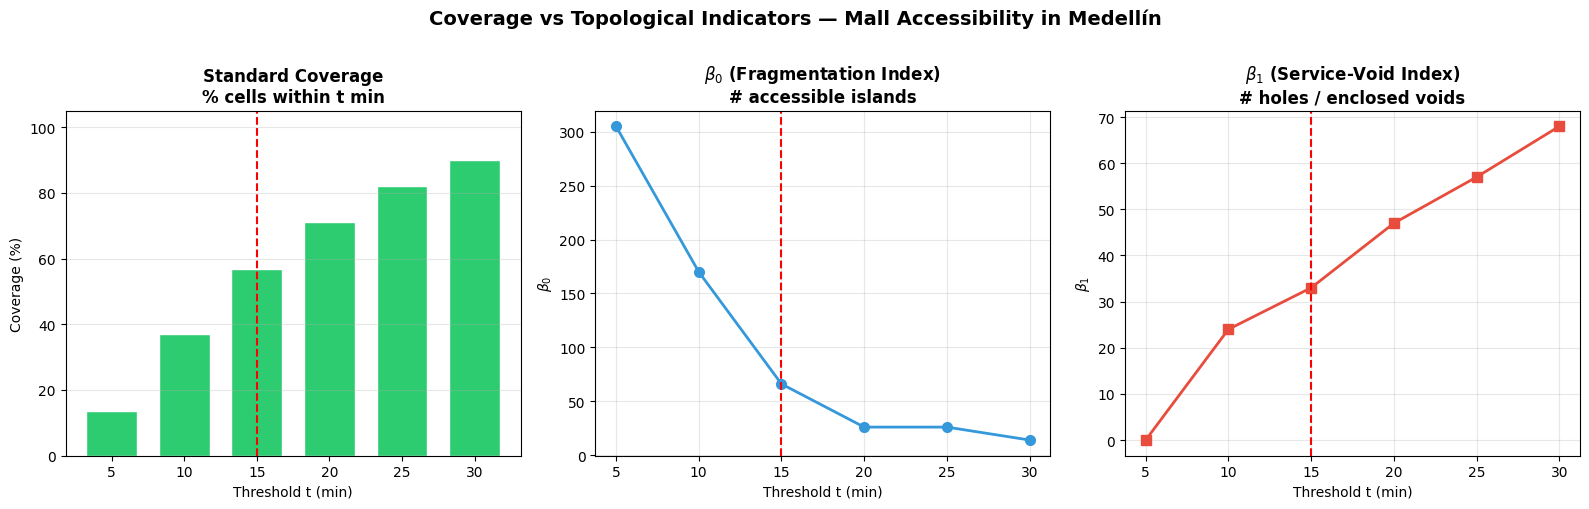

Saved fig08_indicators.png


In [77]:
# ── Summary chart ─────────────────────────────────────────────────────────────
THRESHOLDS_EVAL = [5, 10, 15, 20, 25, 30]

cov    = [100 * (filtration_matrix <= t).sum() / city_cells for t in THRESHOLDS_EVAL]
beta0  = [betti_curve(h0, [t])[0] for t in THRESHOLDS_EVAL]
beta1  = [betti_curve(h1, [t])[0] for t in THRESHOLDS_EVAL]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].bar(THRESHOLDS_EVAL, cov, color='#2ecc71', width=3.5, edgecolor='white')
axes[0].axvline(15, color='red', ls='--', lw=1.5)
axes[0].set_title('Standard Coverage\n% cells within t min', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Threshold t (min)')
axes[0].set_ylabel('Coverage (%)')
axes[0].set_ylim(0, 105)
axes[0].grid(axis='y', alpha=0.3)

axes[1].plot(THRESHOLDS_EVAL, beta0, 'o-', color='#3498db', lw=2, ms=7)
axes[1].axvline(15, color='red', ls='--', lw=1.5)
axes[1].set_title('$\\beta_0$ (Fragmentation Index)\n# accessible islands', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Threshold t (min)')
axes[1].set_ylabel('$\\beta_0$')
axes[1].grid(alpha=0.3)

axes[2].plot(THRESHOLDS_EVAL, beta1, 's-', color='#e74c3c', lw=2, ms=7)
axes[2].axvline(15, color='red', ls='--', lw=1.5)
axes[2].set_title('$\\beta_1$ (Service-Void Index)\n# holes / enclosed voids', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Threshold t (min)')
axes[2].set_ylabel('$\\beta_1$')
axes[2].grid(alpha=0.3)

for ax in axes:
    ax.set_xticks(THRESHOLDS_EVAL)

fig.suptitle('Coverage vs Topological Indicators — Mall Accessibility in Medellín', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig08_indicators.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig08_indicators.png')

## 9 · Service-Void Map (H₁ spatial localisation)

We identify the centroid of each significant H₁ void by finding, for each barcode interval $(b, d)$ with $d > 15$ min, the largest connected cluster of cells whose filtration value is in the range $[b, d]$ (the "donut" of cells that form the void boundary).  

A simpler and more robust proxy: highlight cells where $f(\text{cell})$ is in the range corresponding to the most persistent H₁ features.

In [78]:
from scipy.ndimage import label as scipy_label

# ── For each significant H1 interval, mark cells in that birth-death range ───
# These are the "rim" cells that form or bound the topological void.

# Use top-10 most persistent H1 voids that survive past 15 min
top_voids = sorted(
    [(b, d) for b, d in h1 if d > 15 and d < SENTINEL],
    key=lambda x: x[1] - x[0], reverse=True
)[:10]

print(f'Top-10 H₁ service voids (persistence > 0, death > 15 min):')
for i, (b, d) in enumerate(top_voids):
    print(f'  Void {i+1:2d}: birth={b:.1f} min  death={d:.1f} min  persistence={d-b:.1f} min')

# Build a composite "void likelihood" map:
# a cell is highlighted if its filtration value falls in ANY top void's [b, d] range
void_map = np.zeros(filtration_matrix.shape, dtype=float)
for b, d in top_voids:
    in_range = (filtration_matrix >= b) & (filtration_matrix <= d)
    void_map += in_range.astype(float)

# Normalise
void_map = np.clip(void_map, 0, len(top_voids)) / max(len(top_voids), 1)

Top-10 H₁ service voids (persistence > 0, death > 15 min):
  Void  1: birth=32.4 min  death=116.7 min  persistence=84.2 min
  Void  2: birth=38.4 min  death=117.4 min  persistence=79.0 min
  Void  3: birth=41.5 min  death=117.4 min  persistence=75.9 min
  Void  4: birth=42.1 min  death=117.4 min  persistence=75.3 min
  Void  5: birth=31.7 min  death=86.9 min  persistence=55.2 min
  Void  6: birth=21.4 min  death=41.1 min  persistence=19.6 min
  Void  7: birth=27.9 min  death=47.5 min  persistence=19.6 min
  Void  8: birth=22.4 min  death=41.1 min  persistence=18.7 min
  Void  9: birth=19.0 min  death=35.3 min  persistence=16.2 min
  Void 10: birth=24.9 min  death=41.1 min  persistence=16.2 min


In [ ]:
# ── Plot: Walking-time map + void overlay ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 10))

# Left: standard accessibility
ax = axes[0]
im0 = ax.imshow(
    np.where(filtration_matrix < SENTINEL, filtration_matrix, np.nan),
    origin='lower', cmap='RdYlGn_r', vmin=0, vmax=60, interpolation='nearest'
)
cbar0 = fig.colorbar(im0, ax=ax, fraction=0.04)
cbar0.set_label('Walking time (min)', fontsize=9)
ax.set_title('Standard Accessibility Map\nf(cell) = walking time to nearest mall', fontsize=12, fontweight='bold')
ax.set_xlabel('Col (W→E)')
ax.set_ylabel('Row (S→N)')

# Right: void overlay
ax2 = axes[1]
im_base = ax2.imshow(
    np.where(filtration_matrix <= 15, 1, np.nan),
    origin='lower', cmap='Greens', vmin=0, vmax=1.5, alpha=0.5, interpolation='nearest'
)
im_far = ax2.imshow(
    np.where((filtration_matrix > 15) & (filtration_matrix < SENTINEL), filtration_matrix, np.nan),
    origin='lower', cmap='Oranges', vmin=15, vmax=60, alpha=0.5, interpolation='nearest'
)
# Overlay void zones in strong red
im_void = ax2.imshow(
    np.where(void_map > 0, void_map, np.nan),
    origin='lower', cmap='Reds', vmin=0, vmax=1, alpha=0.75, interpolation='nearest'
)

# Legend patches
patches = [
    mpatches.Patch(color='#27ae60', alpha=0.7, label='Within 15 min (accessible)'),
    mpatches.Patch(color='#e67e22', alpha=0.7, label='15–60 min (limited access)'),
    mpatches.Patch(color='#c0392b', alpha=0.9, label='H₁ void zones (service deserts)'),
]
ax2.legend(handles=patches, loc='upper right', fontsize=8)
ax2.set_title('Topological Service Voids\nH₁ features with death > 15 min', fontsize=12, fontweight='bold')
ax2.set_xlabel('Col (W→E)')
ax2.set_ylabel('Row (S→N)')

fig.suptitle('Mall Accessibility in Medellín — Topological Perspective', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig09_void_map.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig09_void_map.png')

## 10 · Summary and Interpretation

This notebook demonstrates a complete proof-of-concept for applying **persistent homology** to the 15-minute city framework, using shopping malls in Medellín as the service layer.

### What the topology reveals

| Metric | Value | Meaning |
|--------|-------|---------|
| Standard coverage (≤15 min) | see cell above | % of city reachable within 15 min |
| β₀ at t=15 min (fragmentation) | see cell above | # disconnected accessibility islands |
| β₁ at t=15 min (service voids) | see cell above | # enclosed service voids at 15 min |
| H₁ voids persisting past 15 min | see cell above | voids invisible to coverage metrics |

### Topological interpretation

- **H₀ features** represent *fragmentation*: disconnected clusters of accessible cells. A large β₀ at t=15 min means the 15-minute city is not a single connected fabric but a collection of islands around malls.

- **H₁ features** represent *service voids*: holes in the accessibility surface — areas enclosed by accessible zones but themselves inaccessible within the threshold. These are the most novel finding; standard percentage coverage misses them entirely.

- **Betti curves** show how both types of features evolve as the threshold increases, revealing at which point the city starts to "connect" ($β_0 \to 1$) and when voids close ($β_1 \to 0$).

### Next steps for the thesis

1. **Slope-adjusted walking time**: replace Euclidean/OSRM times with slope-corrected Tobler function to capture Medellín's topography
2. **Multiple service types**: repeat for health centers, parks, schools
3. **Neighbourhood comparison**: compute topological indicators per *comuna* and correlate with socioeconomic strata
4. **Population weighting**: weight persistent features by residents inside each void
5. **Formal T₁₅ score**: $T_{15} = \alpha \cdot H_0^{>15} + \beta \cdot H_1^{>15}$

In [ ]:
# Cache the walking-time grid so it does not need to be recomputed each run.
walking_time_mall_path = CITY_PH_ROOT / 'walking_time_mall.parquet'

if walking_time_mall_path.exists():
    grid_gdf = gpd.read_parquet(walking_time_mall_path)
    print(f'Loaded cached grid_gdf from {walking_time_mall_path}')
else:
    grid_gdf.to_parquet(walking_time_mall_path)
    print(f'Saved grid_gdf to {walking_time_mall_path}')

Saved grid_gdf to walking_time_mall.parquet
